In [1]:
import pandas  as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/superstore_cleaned.csv')

In [3]:
# Convert date columns
df['Order Date'] = pd.to_datetime(
    df['Order Date'], errors='coerce'
)
df['Ship Date'] = pd.to_datetime(
    df['Ship Date'], errors='coerce'
)

sns.set_theme(style='whitegrid')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,2017-12-06,NaT,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,2016-11-10,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,2016-11-10,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:


# Check missing dates
print("Missing Order Dates:", df['Order Date'].isna().sum())
print("Missing Ship Dates:", df['Ship Date'].isna().sum())

# Display rows with missing Ship Date
display(
    df[df['Ship Date'].isna()][
        ['Row ID', 'Order ID', 'Order Date', 'Ship Date']
    ].head(10)
)



Missing Order Dates: 5952
Missing Ship Dates: 6096


,Row ID,Order ID,Order Date,Ship Date
2,3,CA-2017-138688,2017-12-06,NaT
3,4,US-2016-108966,2016-11-10,NaT
4,5,US-2016-108966,2016-11-10,NaT
5,6,CA-2015-115812,2015-09-06,NaT
6,7,CA-2015-115812,2015-09-06,NaT
7,8,CA-2015-115812,2015-09-06,NaT
8,9,CA-2015-115812,2015-09-06,NaT
9,10,CA-2015-115812,2015-09-06,NaT
10,11,CA-2015-115812,2015-09-06,NaT
11,12,CA-2015-115812,2015-09-06,NaT


In [7]:

# Check the date values in the current dataset
print("Total rows:", len(df))

print("\nOrder Date examples:")
print(df['Order Date'].head(15))

print("\nShip Date examples:")
print(df['Ship Date'].head(15))

print("\nRows with missing dates:")
display(
    df[df['Order Date'].isna() | df['Ship Date'].isna()][
        ['Row ID', 'Order ID', 'Order Date', 'Ship Date']
    ].head(15)
)


Total rows: 9994

Order Date examples:
0    2017-08-11
1    2017-08-11
2    2017-12-06
3    2016-11-10
4    2016-11-10
5    2015-09-06
6    2015-09-06
7    2015-09-06
8    2015-09-06
9    2015-09-06
10   2015-09-06
11   2015-09-06
12          NaT
13   2017-05-12
14          NaT
Name: Order Date, dtype: datetime64[ns]

Ship Date examples:
0    2017-11-11
1    2017-11-11
2           NaT
3           NaT
4           NaT
5           NaT
6           NaT
7           NaT
8           NaT
9           NaT
10          NaT
11          NaT
12          NaT
13   2017-10-12
14          NaT
Name: Ship Date, dtype: datetime64[ns]

Rows with missing dates:


,Row ID,Order ID,Order Date,Ship Date
2,3,CA-2017-138688,2017-12-06,NaT
3,4,US-2016-108966,2016-11-10,NaT
4,5,US-2016-108966,2016-11-10,NaT
5,6,CA-2015-115812,2015-09-06,NaT
6,7,CA-2015-115812,2015-09-06,NaT
7,8,CA-2015-115812,2015-09-06,NaT
8,9,CA-2015-115812,2015-09-06,NaT
9,10,CA-2015-115812,2015-09-06,NaT
10,11,CA-2015-115812,2015-09-06,NaT
11,12,CA-2015-115812,2015-09-06,NaT


In [8]:

# Reload the cleaned CSV without converting date columns
df_check = pd.read_csv('/content/superstore_cleaned.csv')

print("Original CSV date values:")
display(
    df_check[['Row ID', 'Order Date', 'Ship Date']].head(20)
)

print("\nMissing values in the CSV:")
print(df_check[['Order Date', 'Ship Date']].isna().sum())


Original CSV date values:


,Row ID,Order Date,Ship Date
0,1,08-11-2017,11-11-2017
1,2,08-11-2017,11-11-2017
2,3,12-06-2017,16-06-2017
3,4,11-10-2016,18-10-2016
4,5,11-10-2016,18-10-2016
5,6,09-06-2015,14-06-2015
6,7,09-06-2015,14-06-2015
7,8,09-06-2015,14-06-2015
8,9,09-06-2015,14-06-2015
9,10,09-06-2015,14-06-2015



Missing values in the CSV:
Order Date    0
Ship Date     0
dtype: int64


In [9]:

# Reload the cleaned dataset
df = pd.read_csv('/content/superstore_cleaned.csv')

# Correctly convert dates in DD-MM-YYYY format
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Verify the results
print("Missing Order Dates:", df['Order Date'].isna().sum())
print("Missing Ship Dates:", df['Ship Date'].isna().sum())
print("Dataset shape:", df.shape)

display(df[['Order Date', 'Ship Date']].head(10))


Missing Order Dates: 0
Missing Ship Dates: 0
Dataset shape: (9994, 21)


,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18
5,2015-06-09,2015-06-14
6,2015-06-09,2015-06-14
7,2015-06-09,2015-06-14
8,2015-06-09,2015-06-14
9,2015-06-09,2015-06-14


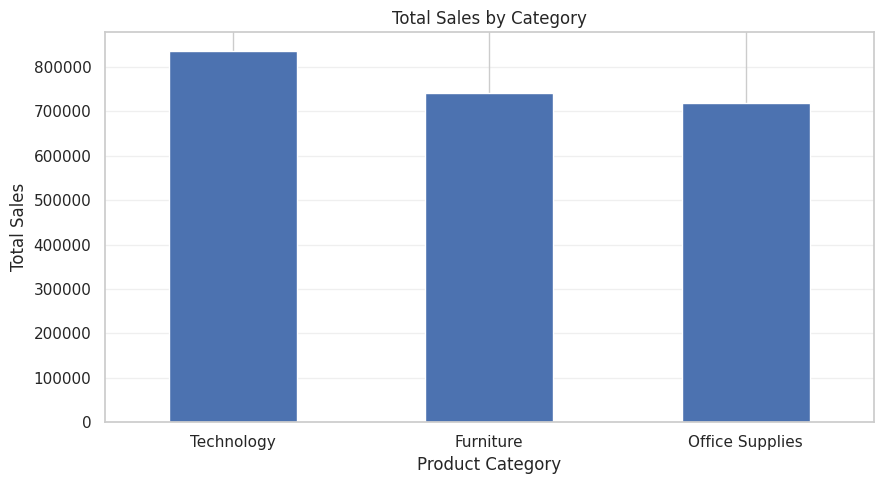

Total Sales by Category:


,Sales
Category,
Technology,836154.03
Furniture,741999.80
Office Supplies,719047.03


In [10]:

# Task 3: Total Sales by Category

category_sales = (
    df.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title('Total Sales by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Display the sales totals
print("Total Sales by Category:")
display(category_sales.round(2))


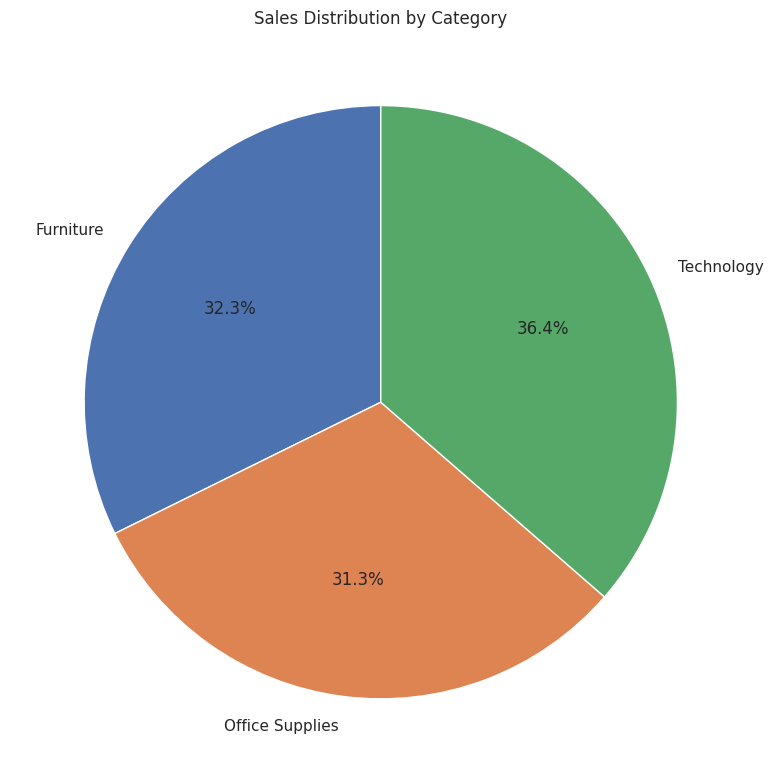

Sales percentage by category:


,Sales
Category,
Furniture,32.3
Office Supplies,31.3
Technology,36.4


In [11]:

# Pie Chart: Sales Distribution by Category

category_sales = df.groupby('Category')['Sales'].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Distribution by Category')
plt.tight_layout()
plt.show()

print("Sales percentage by category:")
display(
    (category_sales / category_sales.sum() * 100).round(2)
)


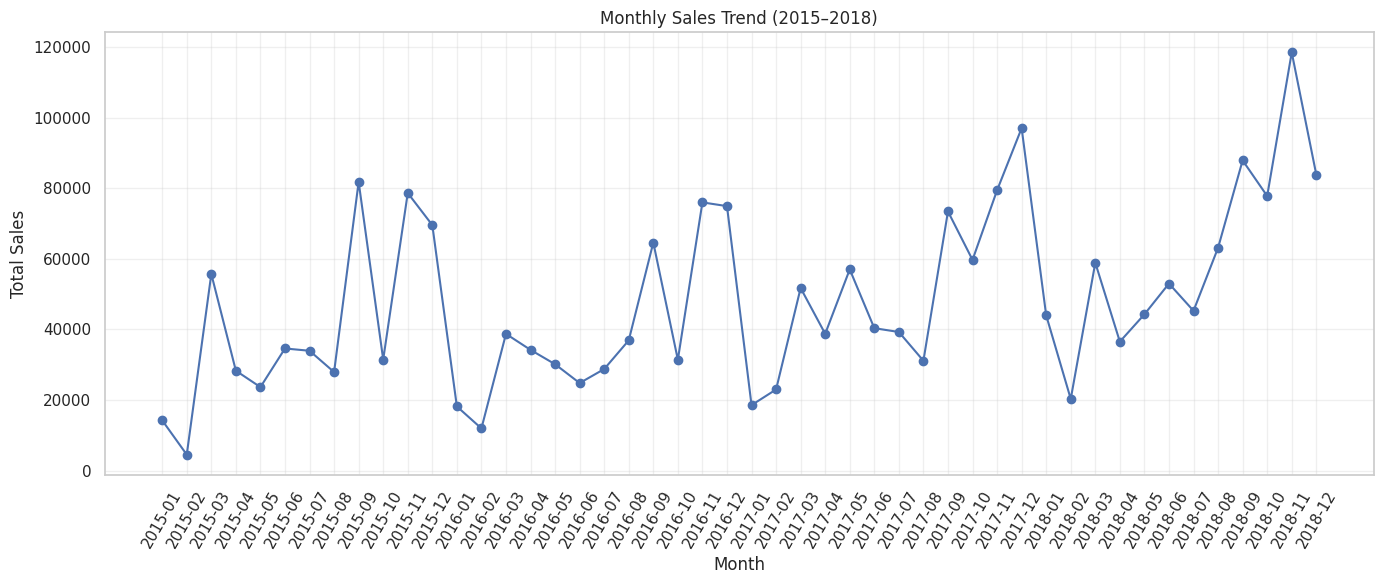

Monthly sales summary:


,Sales
count,48.00
mean,47858.35
std,25195.89
min,4519.89
25%,29790.10
50%,39803.25
75%,65833.34
max,118447.82


In [12]:

# Line Chart: Monthly Sales Trend

df_monthly = df.dropna(subset=['Order Date']).copy()

df_monthly['Year-Month'] = (
    df_monthly['Order Date'].dt.to_period('M')
)

monthly_sales = (
    df_monthly.groupby('Year-Month')['Sales']
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    linewidth=1.5
)

plt.title('Monthly Sales Trend (2015–2018)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Monthly sales summary:")
display(monthly_sales.describe().round(2))


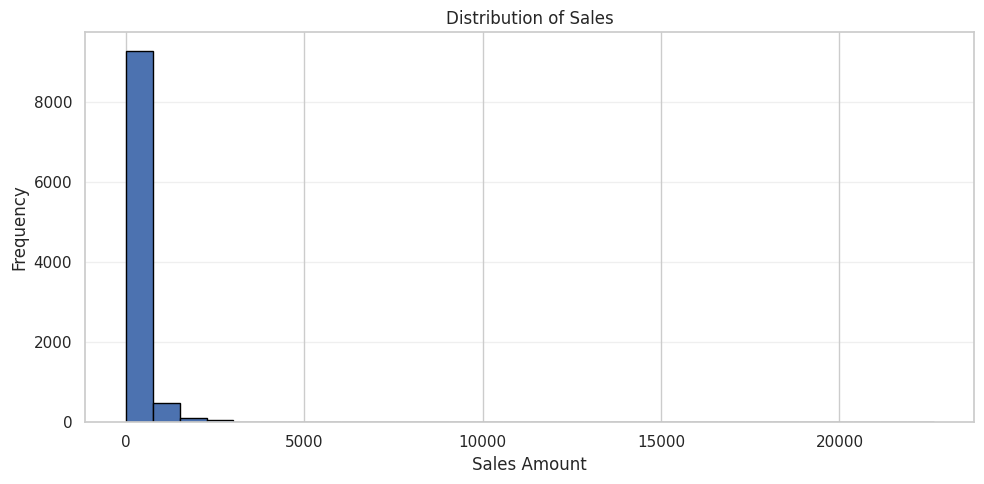

Sales statistics:


,Sales
count,9994.00
mean,229.86
std,623.25
min,0.44
25%,17.28
50%,54.49
75%,209.94
max,22638.48


In [13]:

# Histogram: Distribution of Sales

plt.figure(figsize=(10, 5))

plt.hist(
    df['Sales'].dropna(),
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Sales')
plt.xlabel('Sales Amount')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("Sales statistics:")
display(df['Sales'].describe().round(2))


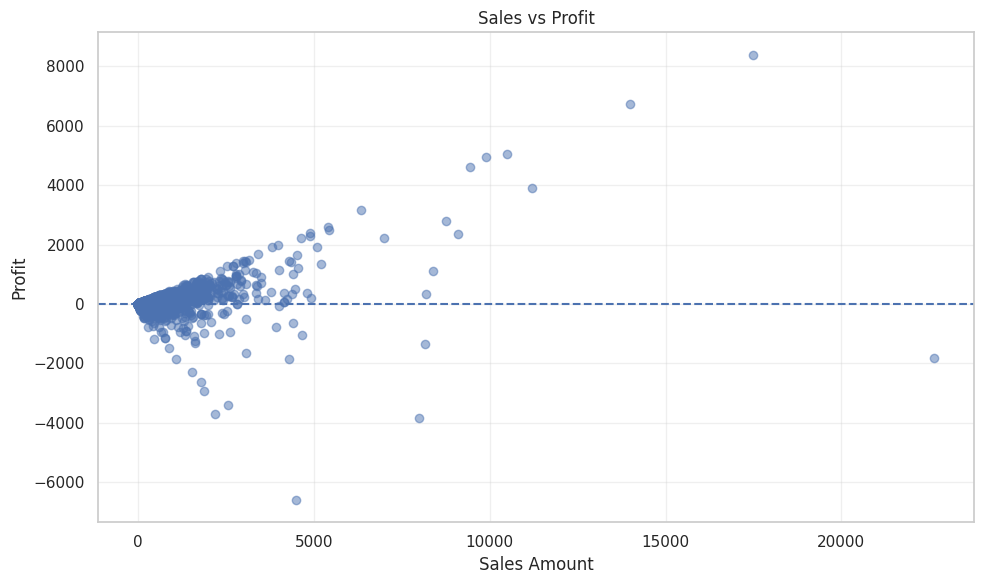

Correlation between Sales and Profit: 0.479


In [14]:

# Scatter Plot: Relationship Between Sales and Profit

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Sales'],
    df['Profit'],
    alpha=0.5
)

plt.title('Sales vs Profit')
plt.xlabel('Sales Amount')
plt.ylabel('Profit')
plt.axhline(y=0, linestyle='--')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation between Sales and Profit:",
      round(df['Sales'].corr(df['Profit']), 3))


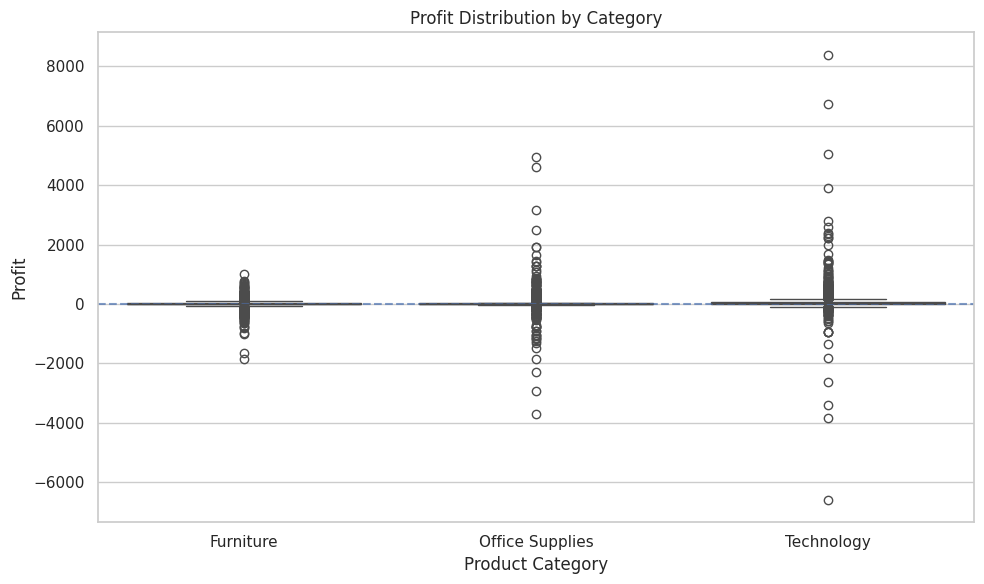

Profit statistics by category:


,count,mean,std,min,25%,50%,75%,max
Category,,,,,,,,
Furniture,2121.0,8.70,136.05,-1862.31,-12.85,7.77,33.73,1013.13
Office Supplies,6026.0,20.33,164.89,-3701.89,2.10,6.88,19.42,4946.37
Technology,1847.0,78.75,428.82,-6599.98,5.20,25.02,74.89,8399.98


In [15]:

# Box Plot: Profit Distribution by Category

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Category',
    y='Profit'
)

plt.title('Profit Distribution by Category')
plt.xlabel('Product Category')
plt.ylabel('Profit')
plt.axhline(y=0, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Profit statistics by category:")
display(
    df.groupby('Category')['Profit']
    .describe()
    .round(2)
)


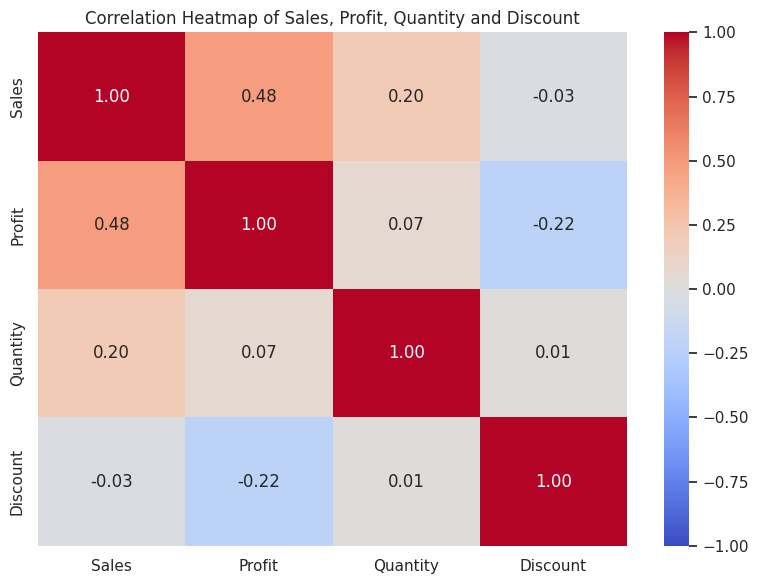

In [16]:

# Correlation Heatmap

numeric_columns = ['Sales', 'Profit', 'Quantity', 'Discount']

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Sales, Profit, Quantity and Discount')
plt.tight_layout()
plt.show()
